# SPLIT: real spatial counts and a direct R comparison

This executable example uses 240 spots and 512 genes from the real **DLPFC 151673** slice (spatialLIBD). Counts and coordinates are measured. Reference profiles are within-slice cortical-layer means and weights are fitted by NNLS: these are illustrative inputs, **not independent cell-type references, RCTD outputs, or biological ground truth**. Consequently the figures demonstrate execution, not a proven improvement in decontamination.

The attached compact input includes R outputs generated from unmodified SPLIT commit `f226987f0fecf2847646bda50a64886e0ea432a9`. Purification is compared directly. Reassignment uses the same neighbor graph and balance decisions to isolate the numerical kernel. Spatial scoring and label swapping are not claimed to have complete R parity.

Install `splitst`, `anndata`, `numpy`, `pandas`, `scipy`, and `matplotlib`; run from this notebook's folder. OmicVerse exposes the corresponding `ov.space.split_*` functions; use a version containing the second-type recipient repair.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from anndata import AnnData
from scipy import sparse
import splitst

fixture = np.load(Path('fixtures/split_dlpfc_151673.npz'))
adata = AnnData(fixture['counts'], obs=pd.DataFrame(index=fixture['cells']), var=pd.DataFrame(index=fixture['genes']))
adata.layers['counts'] = adata.X.copy()
adata.obsm['spatial'] = fixture['coords']
weights = pd.DataFrame(fixture['weights'], index=adata.obs_names, columns=fixture['types'])
reference = pd.DataFrame(fixture['reference'], index=fixture['types'], columns=adata.var_names)
print(adata.shape)

(240, 512)


In [2]:
splitst.purify(adata, weights, reference)
splitst.spatial_score(adata, weights, adata.obs['first_type'], k=12)
splitst.balance(adata, threshold=0.15)
splitst.reassign_residuals(adata, k=12, receiver_policy='second_type')
print(adata.uns['split_residual_stats'])

{'raw_total': 595261.0, 'purified_total': 490850.9039339841, 'positive_residual_total': 104410.0960660159, 'assigned_residual_total': 104410.0960660159, 'self_kept_residual_total': 0.0, 'unassigned_residual_total': 0.0, 'n_sender_cells': 108, 'n_sender_cells_with_receivers': 108, 'mode': 'count_proportional', 'k': 12, 'radius': None, 'self_keep': 0.0, 'receiver_policy': 'second_type'}


Residuals go only to neighbors whose primary type matches the sender's secondary type; rejected neighbors are excluded when `spot_class` is available. `receiver_policy='all'` explicitly selects the former Python-only behavior. Unassigned residuals remain reported separately.

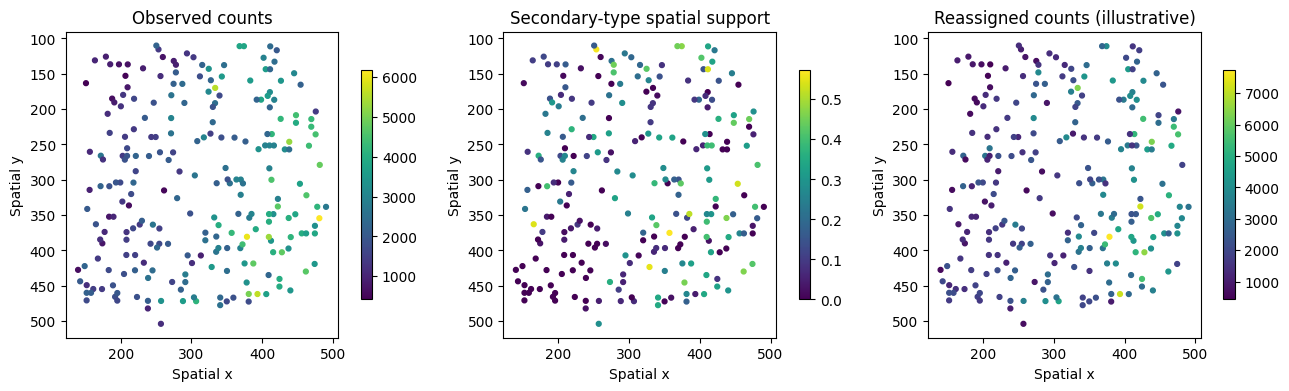

In [3]:
xy = adata.obsm['spatial']
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
values = [np.asarray(adata.layers['counts'].sum(axis=1)).ravel(), adata.obs['neighborhood_weights_second_type'].to_numpy(), np.asarray(adata.layers['split_reassigned'].sum(axis=1)).ravel()]
for ax, value, title in zip(axes, values, ['Observed counts', 'Secondary-type spatial support', 'Reassigned counts (illustrative)']):
    image = ax.scatter(xy[:,0], xy[:,1], c=value, s=12, cmap='viridis')
    ax.set(title=title, xlabel='Spatial x', ylabel='Spatial y', aspect='equal')
    ax.invert_yaxis()
    fig.colorbar(image, ax=ax, shrink=0.75)
plt.show()

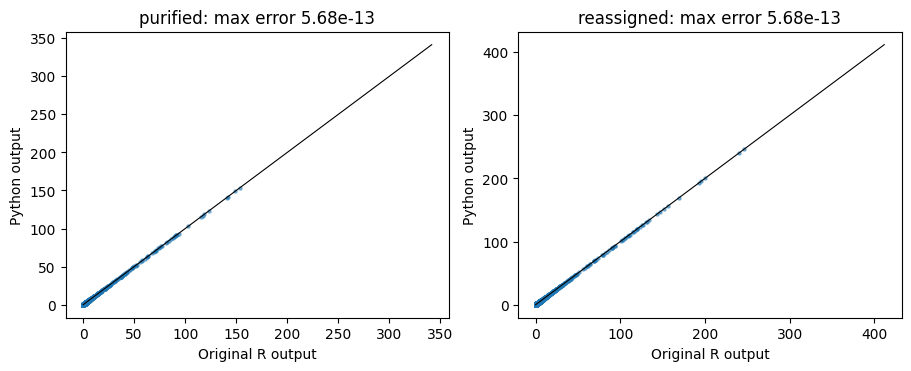

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), constrained_layout=True)
for ax, key in zip(axes, ['purified', 'reassigned']):
    py = adata.layers['split_' + key]
    py = py.toarray() if sparse.issparse(py) else py
    expected = fixture['r_' + key]
    np.testing.assert_allclose(py, expected, rtol=1e-9, atol=1e-10)
    ax.scatter(expected.ravel()[::20], py.ravel()[::20], s=5, alpha=0.5)
    lim = max(expected.max(), py.max())
    ax.plot([0, lim], [0, lim], color='black', linewidth=0.8)
    ax.set(title=f'{key}: max error {np.max(abs(py-expected)):.2e}', xlabel='Original R output', ylabel='Python output')
plt.show()